# VisionBridge – VizWiz Baseline VQA Experiment

**Purpose:** This notebook is independent of the friend's EDA notebook. It downloads the official VizWiz validation images/annotations, performs basic EDA, runs a pretrained BLIP VQA baseline, and saves results that can be used in the VisionBridge report.



**Important:** The BLIP model used here is a general pretrained VQA model, not a model trained specifically on VizWiz. Therefore, report the result as a **baseline/initial benchmark**, not as the final VisionBridge result.


## What this notebook will produce

1. Dataset counts and answerability statistics.
2. A question-length analysis.
3. A few sample predictions.
4. Baseline VQA accuracy on a configurable validation subset.
5. A CSV containing predictions.
6. A confusion-style summary for answerable vs. unanswerable questions.
7. A bar chart that can be used in the report.

The official VizWiz dataset contains 10 crowdsourced answers for each train/validation question and also includes an `answerable` field.


In [5]:
# CELL 1 — Check GPU
import torch, os, platform

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU is not enabled. In Colab choose Runtime > Change runtime type > T4 GPU.")


PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [10]:
# CELL 2 — Fix/install compatible packages

!pip uninstall -y Pillow
!pip install -q Pillow==11.3.0
!pip install -q -U transformers accelerate sentencepiece pandas matplotlib tqdm

Found existing installation: pillow 12.3.0
Uninstalling pillow-12.3.0:
  Successfully uninstalled pillow-12.3.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 60.4 MB/s eta 0:00:00


In [1]:
# CELL 3 — Imports
import os
import json
import zipfile
import glob
import re
import math
import time
import random
import shutil
import subprocess
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
from transformers import BlipProcessor, BlipForQuestionAnswering

print("Imports completed.")


Imports completed.


## 1. Download the official VizWiz validation data

This notebook only needs the **validation split** for the baseline experiment. The official dataset loader points to the VizWiz validation image archive and the official `Annotations.zip`. ]


In [2]:
# CELL 4 — Download official validation images and annotations
BASE = "/content/vizwiz"
os.makedirs(BASE, exist_ok=True)

VAL_URL = "https://vizwiz.cs.colorado.edu/VizWiz_final/images/val.zip"
ANN_URL = "https://vizwiz.cs.colorado.edu/VizWiz_final/vqa_data/Annotations.zip"

val_zip = f"{BASE}/val.zip"
ann_zip = f"{BASE}/Annotations.zip"

if not os.path.exists(val_zip):
    print("Downloading validation images...")
    !wget -q --show-progress -O "{val_zip}" "{VAL_URL}"
else:
    print("Validation zip already exists.")

if not os.path.exists(ann_zip):
    print("Downloading annotations...")
    !wget -q --show-progress -O "{ann_zip}" "{ANN_URL}"
else:
    print("Annotations zip already exists.")

print("Downloads completed.")


/content/vizwiz/val 100%[===================>]   3.25G  26.7MB/s    in 2m 26s  
/content/vizwiz/Ann 100%[===================>]   1.63M  5.37MB/s    in 0.3s    
Downloads completed.


In [3]:
# CELL 5 — Extract files
VAL_DIR = f"{BASE}/val_images"
ANN_DIR = f"{BASE}/annotations"

os.makedirs(VAL_DIR, exist_ok=True)
os.makedirs(ANN_DIR, exist_ok=True)

if not os.path.exists(f"{ANN_DIR}/val.json"):
    with zipfile.ZipFile(ann_zip, "r") as z:
        z.extractall(ANN_DIR)

if not os.path.exists(f"{VAL_DIR}/val"):
    with zipfile.ZipFile(val_zip, "r") as z:
        z.extractall(VAL_DIR)

print("Annotation files:", glob.glob(ANN_DIR + "/**/*", recursive=True)[:10])
print("Image folders:", glob.glob(VAL_DIR + "/**/", recursive=True)[:10])


Annotation files: ['/content/vizwiz/annotations/val.json', '/content/vizwiz/annotations/train.json', '/content/vizwiz/annotations/test.json']
Image folders: ['/content/vizwiz/val_images/', '/content/vizwiz/val_images/val/']


In [4]:
# CELL 6 — Locate val.json and image directory
val_json_candidates = glob.glob(ANN_DIR + "/**/val.json", recursive=True)
image_candidates = glob.glob(VAL_DIR + "/**/val", recursive=True)

assert len(val_json_candidates) > 0, "val.json was not found."
assert len(image_candidates) > 0, "Validation image folder was not found."

VAL_JSON = val_json_candidates[0]
IMAGE_DIR = image_candidates[0]

print("VAL_JSON:", VAL_JSON)
print("IMAGE_DIR:", IMAGE_DIR)
print("Number of image files:", len(glob.glob(IMAGE_DIR + "/*")))


VAL_JSON: /content/vizwiz/annotations/val.json
IMAGE_DIR: /content/vizwiz/val_images/val
Number of image files: 7750


## 2. Load the validation annotations

The official format contains the image filename, question, 10 answers, answer type and an `answerable` value.

In [5]:
# CELL 7 — Load annotations
with open(VAL_JSON, "r") as f:
    val_data = json.load(f)

print("Validation questions:", len(val_data))
print("First record keys:", val_data[0].keys())
print(json.dumps(val_data[0], indent=2)[:2500])


Validation questions: 4319
First record keys: dict_keys(['image', 'question', 'answers', 'answer_type', 'answerable'])
{
  "image": "VizWiz_val_00000000.jpg",
  "question": "Ok. There is another picture I hope it is a better one.",
  "answers": [
    {
      "answer": "unanswerable",
      "answer_confidence": "yes"
    },
    {
      "answer": "unanswerable",
      "answer_confidence": "yes"
    },
    {
      "answer": "unanswerable",
      "answer_confidence": "yes"
    },
    {
      "answer": "unanswerable",
      "answer_confidence": "yes"
    },
    {
      "answer": "unanswerable",
      "answer_confidence": "maybe"
    },
    {
      "answer": "unanswerable",
      "answer_confidence": "yes"
    },
    {
      "answer": "unanswerable",
      "answer_confidence": "yes"
    },
    {
      "answer": "unanswerable",
      "answer_confidence": "no"
    },
    {
      "answer": "cannot repair this computer automatically",
      "answer_confidence": "maybe"
    },
    {
      "answer

In [6]:
# CELL 8 — Basic EDA
def safe_word_count(text):
    return len(str(text).strip().split())

df = pd.DataFrame(val_data)

df["question_length"] = df["question"].apply(safe_word_count)
df["answerable_label"] = df["answerable"].astype(int)

print("Validation rows:", len(df))
print("Answerable:", (df["answerable"] == 1).sum())
print("Unanswerable:", (df["answerable"] == 0).sum())
print("Unanswerable percentage:", round((df["answerable"] == 0).mean() * 100, 2), "%")
print("Average question length:", round(df["question_length"].mean(), 2))
print("Median question length:", df["question_length"].median())

print("\nAnswer types:")
print(df["answer_type"].value_counts(dropna=False))


Validation rows: 4319
Answerable: 2934
Unanswerable: 1385
Unanswerable percentage: 32.07 %
Average question length: 7.17
Median question length: 5.0

Answer types:
answer_type
other           2691
unanswerable    1385
yes/no           195
number            48
Name: count, dtype: int64


question
what      2630
can        330
what's     224
is         209
i           67
how         67
please      66
which       55
this        41
could       41
Name: count, dtype: int64


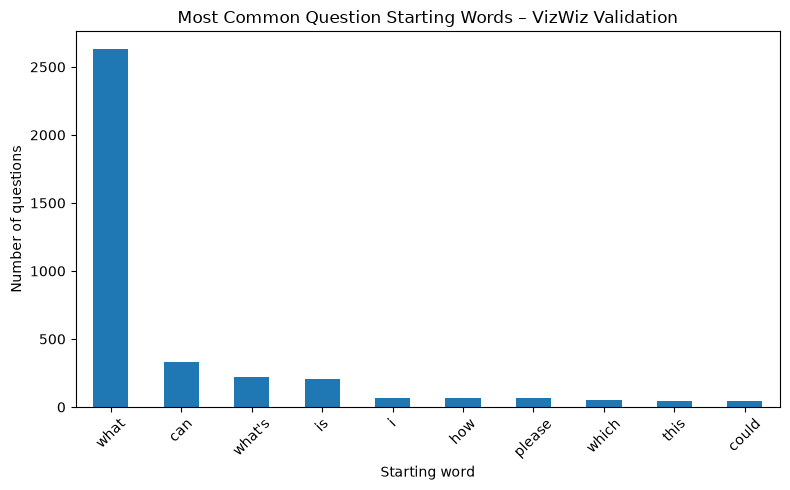

In [7]:
# CELL 9 — Question-start analysis
question_starts = df["question"].str.lower().str.strip().str.split().str[0]
top_starts = question_starts.value_counts().head(10)

print(top_starts)

plt.figure(figsize=(8,5))
top_starts.plot(kind="bar")
plt.title("Most Common Question Starting Words – VizWiz Validation")
plt.xlabel("Starting word")
plt.ylabel("Number of questions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 3. Load the pretrained BLIP VQA baseline

We use `Salesforce/blip-vqa-base`. The official model card provides the Transformers loading method for this VQA model.

**Do not call this the VisionBridge model yet.** It is only the baseline used to obtain an initial quantitative result.


In [8]:
# CELL 10 — Load BLIP VQA
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

processor = BlipProcessor.from_pretrained("Salesforce/blip-vqa-base")
model = BlipForQuestionAnswering.from_pretrained("Salesforce/blip-vqa-base")
model = model.to(device)
model.eval()

print("BLIP VQA model loaded.")


Using: cuda


preprocessor_config.json:   0%|          | 0.00/445 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.54GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/788 [00:00<?, ?it/s]

BLIP VQA model loaded.


In [25]:
# CELL 11 — Evaluation configuration
SEED = 42
random.seed(SEED)

# FIRST RUN: keep 200.
# AFTER SUCCESS: try 500 or 1000.
EVAL_SIZE = 500

eval_df = df.sample(n=min(EVAL_SIZE, len(df)), random_state=SEED).reset_index(drop=True)

print("Evaluation samples:", len(eval_df))
print("Answerable:", eval_df["answerable"].sum())
print("Unanswerable:", (eval_df["answerable"] == 0).sum())


Evaluation samples: 500
Answerable: 351
Unanswerable: 149


In [26]:
# CELL 12 — Fixed VizWiz answer processing and scoring

def get_answer_text(answer):
    """Convert VizWiz answer entry into plain text."""
    if isinstance(answer, dict):
        return str(answer.get("answer", ""))
    return str(answer)

def normalize_answer(s):
    s = str(s).lower().strip()
    s = re.sub(r"[^a-z0-9 ]+", " ", s)
    s = re.sub(r"\s+", " ", s)
    return s.strip()

def vizwiz_score(prediction, answers):
    """
    VQA-style soft score using the 10 human answers.
    """
    pred = normalize_answer(prediction)

    refs = [
        normalize_answer(get_answer_text(a))
        for a in answers
    ]

    matches = sum(1 for a in refs if a == pred)

    return min(1.0, matches / 3.0)

def exact_match_any(prediction, answers):
    pred = normalize_answer(prediction)

    refs = [
        normalize_answer(get_answer_text(a))
        for a in answers
    ]

    return int(pred in refs)

print("Answer processing functions loaded successfully.")

Answer processing functions loaded successfully.


In [27]:
# CELL 13 — Run baseline predictions

results = []

for i, row in tqdm(eval_df.iterrows(), total=len(eval_df)):

    image_path = os.path.join(IMAGE_DIR, row["image"])

    try:
        # Load image
        image = Image.open(image_path).convert("RGB")

        # Question
        question = row["question"]

        # Prepare model input
        inputs = processor(
            image,
            question,
            return_tensors="pt"
        ).to(device)

        # Generate answer
        with torch.no_grad():
            output = model.generate(
                **inputs,
                max_new_tokens=20
            )

        prediction = processor.decode(
            output[0],
            skip_special_tokens=True
        ).strip()

        # Calculate scores
        score = vizwiz_score(
            prediction,
            row["answers"]
        )

        exact = exact_match_any(
            prediction,
            row["answers"]
        )

        # Convert dictionary answers into readable strings
        answer_texts = [
            get_answer_text(a)
            for a in row["answers"]
        ]

        results.append({
            "image": row["image"],
            "question": question,
            "prediction": prediction,
            "answers": " | ".join(answer_texts),
            "answerable": int(row["answerable"]),
            "answer_type": row["answer_type"],
            "vizwiz_soft_score": score,
            "exact_match_any": exact
        })

    except Exception as e:
        print("Error:", row["image"], e)

results_df = pd.DataFrame(results)

print("Completed predictions:", len(results_df))

results_df.head()

  0%|          | 0/500 [00:00<?, ?it/s]

Completed predictions: 500


,image,question,prediction,answers,answerable,answer_type,vizwiz_soft_score,exact_match_any
0,VizWiz_val_00000314.jpg,Can you please tell me not to compare skin cel...,yes,unanswerable | dont compare skin cells | unans...,0,unanswerable,0.333333,1
1,VizWiz_val_00004284.jpg,What is this?,bottle,unanswerable | sd | unanswerable | unanswerabl...,0,unanswerable,0.000000,0
2,VizWiz_val_00000734.jpg,What color is this and what is it?,brown,brown teddy bear | brown teddy bear | brown be...,1,other,0.000000,0
3,VizWiz_val_00000151.jpg,"Okay, I moved the camera a little to the right...",yes,unanswerable | unanswerable | unanswerable | u...,0,unanswerable,0.000000,0
4,VizWiz_val_00000109.jpg,What is the expiration date on this bus pass?,5,unanswerable | unanswerable | unanswerable | u...,0,unanswerable,0.000000,0


In [28]:
# CELL 14 — Calculate baseline results
if len(results_df) == 0:
    raise RuntimeError("No predictions were produced.")

soft_score = results_df["vizwiz_soft_score"].mean()
exact_score = results_df["exact_match_any"].mean()

print("=" * 50)
print("VISIONBRIDGE BASELINE RESULTS")
print("=" * 50)
print("Evaluation samples:", len(results_df))
print("VQA-style soft score:", round(soft_score * 100, 2), "%")
print("Exact match with at least one human answer:", round(exact_score * 100, 2), "%")
print("=" * 50)

print("\nResults by answerability:")
print(
    results_df.groupby("answerable")[["vizwiz_soft_score", "exact_match_any"]]
    .mean()
    .rename(index={0: "Unanswerable", 1: "Answerable"})
)


VISIONBRIDGE BASELINE RESULTS
Evaluation samples: 500
VQA-style soft score: 25.13 %
Exact match with at least one human answer: 33.6 %

Results by answerability:
              vizwiz_soft_score  exact_match_any
answerable                                      
Unanswerable           0.093960         0.208054
Answerable             0.318139         0.390313


In [31]:
# CELL 15 — Save results
RESULT_DIR = "/content/visionbridge_results"
os.makedirs(RESULT_DIR, exist_ok=True)

csv_path = os.path.join(RESULT_DIR, "vizwiz_blip_baseline_predictions.csv")
results_df.to_csv(csv_path, index=False)

summary = pd.DataFrame({
    "metric": [
        "Evaluation samples",
        "VQA-style soft score",
        "Exact match any reference",
        "Answerable samples",
        "Unanswerable samples"
    ],
    "value": [
        len(results_df),
        soft_score,
        exact_score,
        int(results_df["answerable"].sum()),
        int((results_df["answerable"] == 0).sum())
    ]
})

summary_path = os.path.join(RESULT_DIR, "baseline_summary.csv")
summary.to_csv(summary_path, index=False)

print("Saved:", csv_path)
print("Saved:", summary_path)


Saved: /content/visionbridge_results/vizwiz_blip_baseline_predictions.csv
Saved: /content/visionbridge_results/baseline_summary.csv


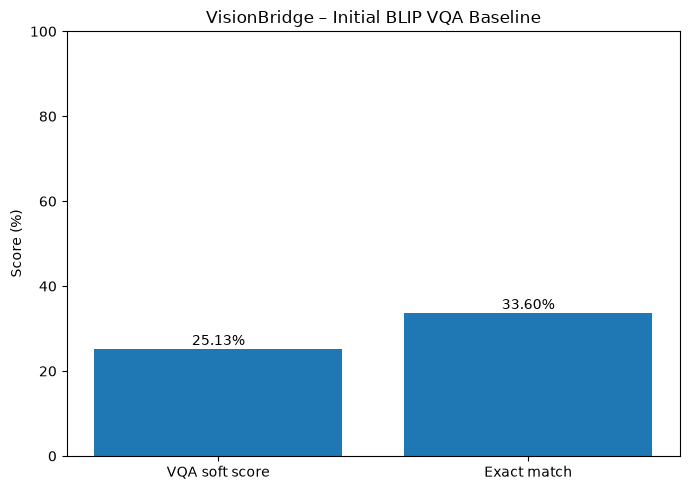

Saved: /content/visionbridge_results/baseline_results.png


In [32]:
# CELL 16 — Plot report-ready baseline results
plot_df = pd.DataFrame({
    "Metric": ["VQA soft score", "Exact match"],
    "Score (%)": [soft_score * 100, exact_score * 100]
})

plt.figure(figsize=(7,5))
plt.bar(plot_df["Metric"], plot_df["Score (%)"])
plt.ylabel("Score (%)")
plt.title("VisionBridge – Initial BLIP VQA Baseline")
plt.ylim(0, max(100, plot_df["Score (%)"].max() * 1.25))
for i, v in enumerate(plot_df["Score (%)"]):
    plt.text(i, v + 1, f"{v:.2f}%", ha="center")
plt.tight_layout()

plot_path = os.path.join(RESULT_DIR, "baseline_results.png")
plt.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", plot_path)


In [33]:
# CELL 17 — Show sample predictions
display(
    results_df[
        ["question", "prediction", "answers", "answerable", "vizwiz_soft_score"]
    ].head(20)
)


,question,prediction,answers,answerable,vizwiz_soft_score
0,Can you please tell me not to compare skin cel...,yes,unanswerable | dont compare skin cells | unans...,0,0.333333
1,What is this?,bottle,unanswerable | sd | unanswerable | unanswerabl...,0,0.000000
2,What color is this and what is it?,brown,brown teddy bear | brown teddy bear | brown be...,1,0.000000
3,"Okay, I moved the camera a little to the right...",yes,unanswerable | unanswerable | unanswerable | u...,0,0.000000
4,What is the expiration date on this bus pass?,5,unanswerable | unanswerable | unanswerable | u...,0,0.000000
5,Does this shoe have a stiletto heel?,yes,yes | no | yes | yes | yes | yes | yes | yes |...,1,1.000000
6,I turned the box to the next side. Can you tel...,no,once daily vitamin | woments 1 daily | womens ...,1,0.000000
7,What is in this bottle?,vitamin water,unanswerable | aspirin | unanswerable | vitami...,0,0.000000
8,Can you tell what soda this is?,yes,bolo | dr pepper 10 | dr pepper 10 | dr pepper...,1,0.333333
9,WHat is this?,ford,ford logo | ford logo | ford | ford logo patch...,1,1.000000


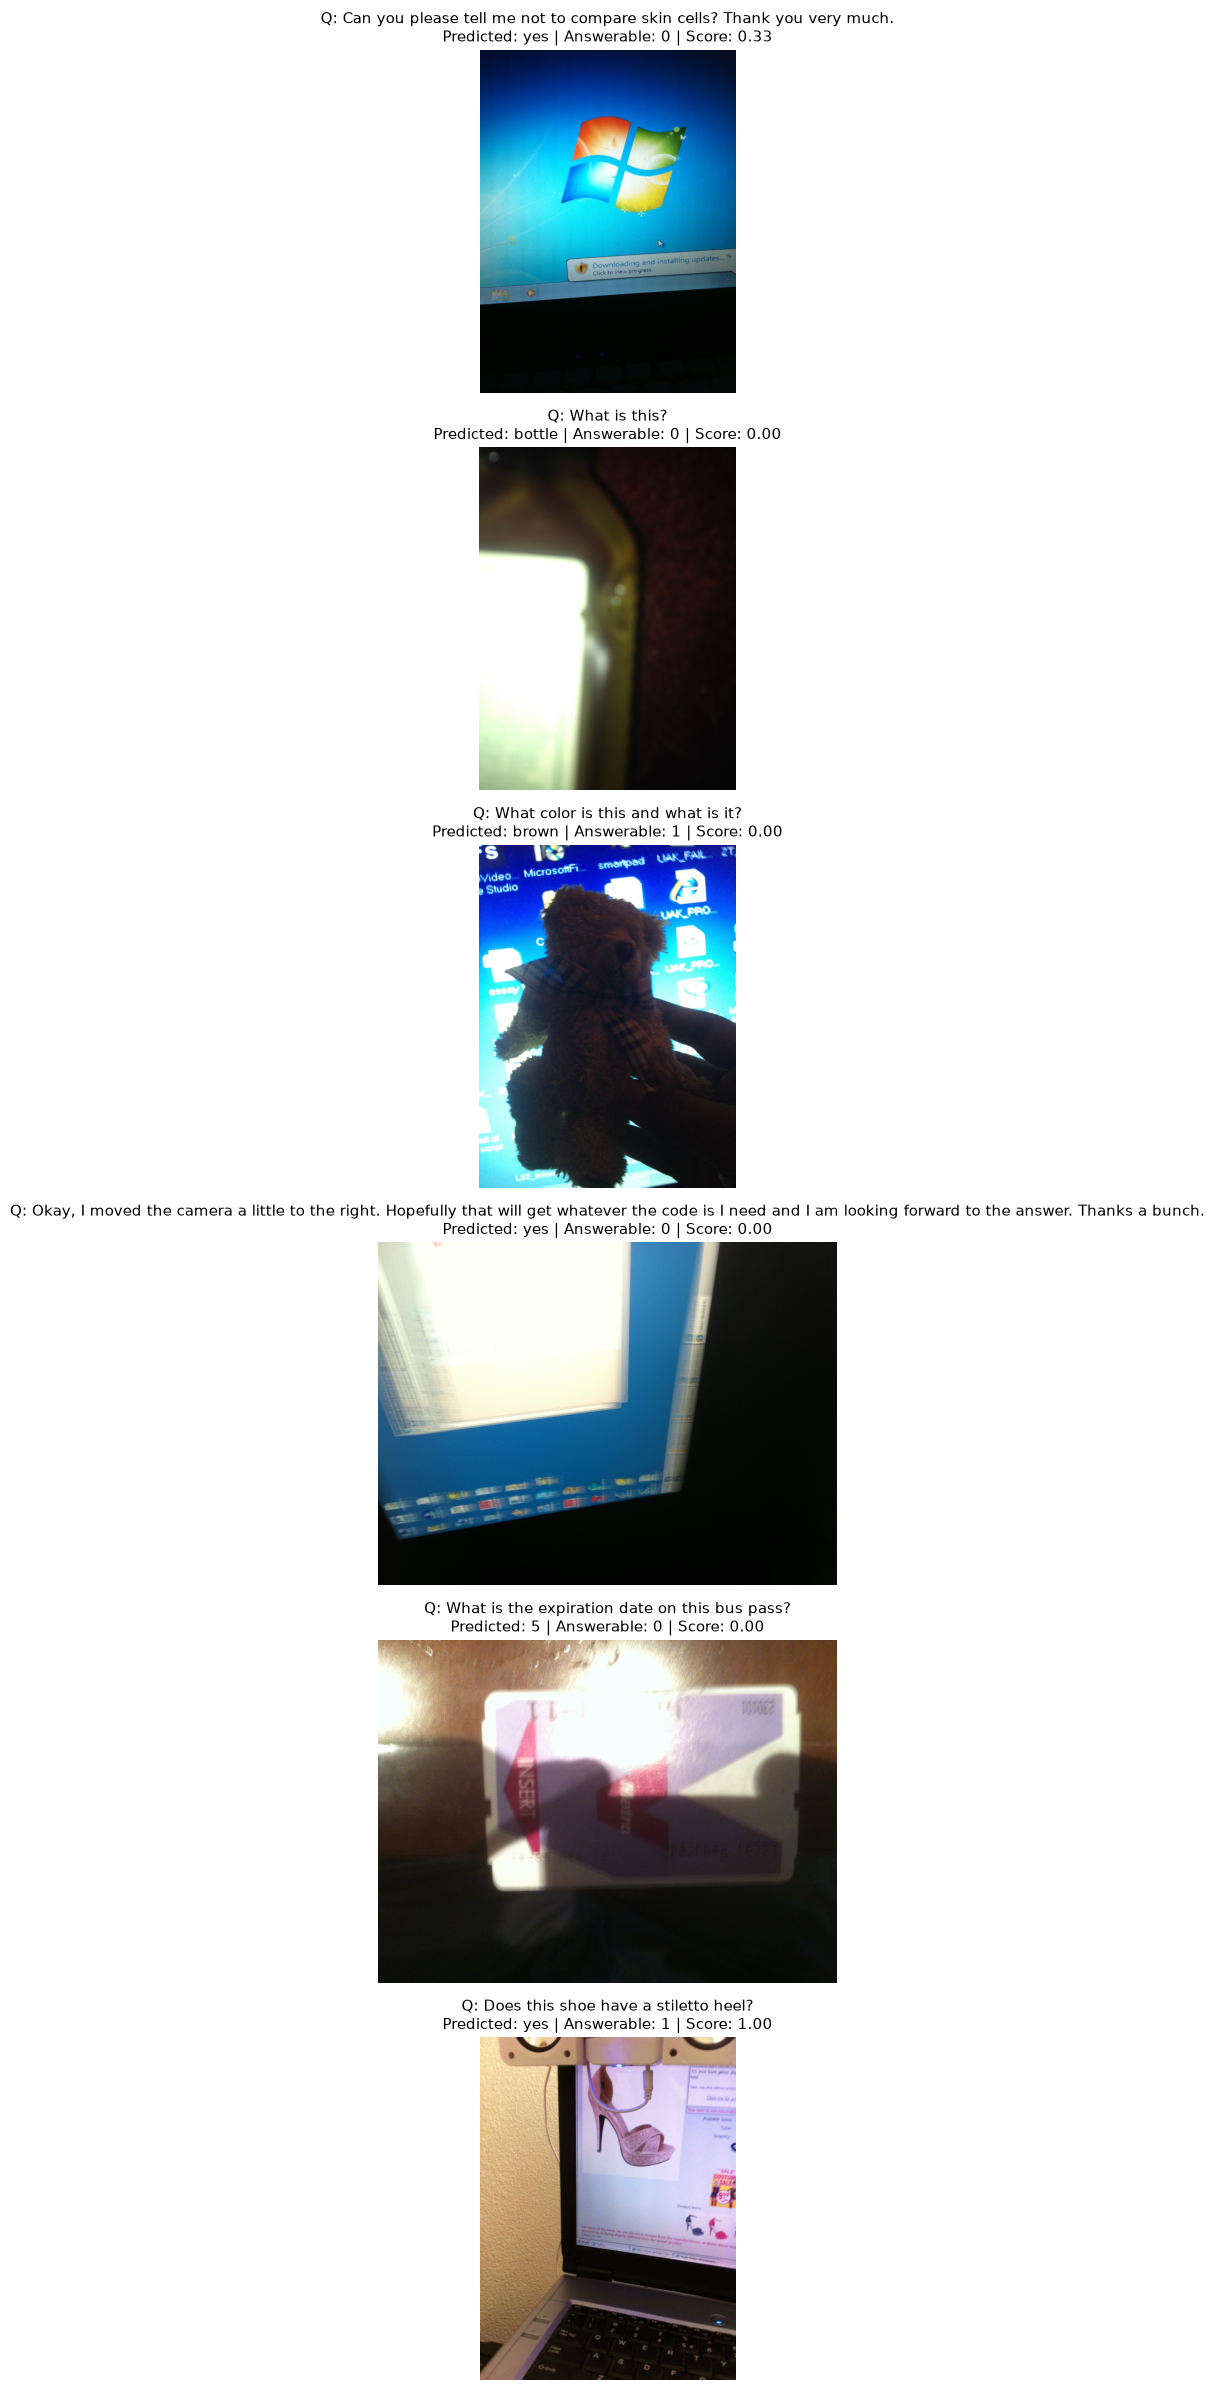

Saved: /content/visionbridge_results/qualitative_predictions.png


In [34]:
# CELL 18 — Display sample image + prediction
import matplotlib.pyplot as plt

n_show = min(6, len(results_df))
sample_rows = results_df.head(n_show)

fig, axes = plt.subplots(n_show, 1, figsize=(12, 4*n_show))
if n_show == 1:
    axes = [axes]

for ax, (_, r) in zip(axes, sample_rows.iterrows()):
    image_path = os.path.join(IMAGE_DIR, r["image"])
    image = Image.open(image_path).convert("RGB")

    ax.imshow(image)
    ax.axis("off")
    ax.set_title(
        f"Q: {r['question']}\n"
        f"Predicted: {r['prediction']} | "
        f"Answerable: {r['answerable']} | "
        f"Score: {r['vizwiz_soft_score']:.2f}",
        fontsize=11
    )

plt.tight_layout()
qual_path = os.path.join(RESULT_DIR, "qualitative_predictions.png")
plt.savefig(qual_path, dpi=150, bbox_inches="tight")
plt.show()

print("Saved:", qual_path)
